# Week 0: Your Toolkit (Python, OOP, NumPy, pandas, matplotlib)

**How Machines Know and Find What You Like** | WiDS 6.0, Analytics Club, IIT Bombay

Welcome! Before we teach a computer what you like, we need four tools. This notebook introduces each one gently, with small demos you can run and change.

| Part | Tool | What it does for us |
|---|---|---|
| 1 | Python basics | Store and loop over data |
| 2 | Classes (OOP) | Bundle data and actions together, like a `Movie` |
| 3 | NumPy | Fast maths on lists of numbers (vectors) |
| 4 | pandas | Tables, like Excel inside Python |
| 5 | matplotlib | Charts |
| 6 | Mini challenge | Use all of them together |

### How to use this notebook

- Click a grey code cell and press **Shift + Enter** to run it. The output appears below.
- Run the cells **from top to bottom**. Later cells use things made in earlier ones.
- **Change things and break them.** You cannot damage anything. If it gets messy, use **Runtime > Restart session** and run again from the top.
- Cells marked **Try it** are for you. Answers are at the very end.

Time needed: about 3 to 4 hours, spread over a few days. No ML knowledge is needed.

> Our running example: four hostel friends (Aarav, Meera, Kabir and Zoya) who rate movies from 1 (hated it) to 5 (loved it). You will meet them again in Week 1.

---
## Part 1: Python basics in 10 minutes

If you already know Python, skim this part and move to Part 2.

A **variable** is a name for a value. A **list** is an ordered collection. A **dictionary** maps keys to values.

In [1]:
# A variable: a name for a value
movie = "3 Idiots"
rating = 5
print(movie, "got a rating of", rating)

# A list: values in order (positions start at 0)
aarav_ratings = [5, 4, 1, 1]
print("First rating:", aarav_ratings[0])
print("Number of ratings:", len(aarav_ratings))

# A dictionary: look up a value by its key
genre_of = {"3 Idiots": "comedy", "Interstellar": "sci-fi"}
print("Interstellar is a", genre_of["Interstellar"], "movie")

3 Idiots got a rating of 5
First rating: 5
Number of ratings: 4
Interstellar is a sci-fi movie


A **loop** repeats work for every item. A **function** is a reusable recipe: give it inputs, it gives back an output.

In [2]:
movies = ["3 Idiots", "Dangal", "Interstellar", "Inception"]

# Loop over two lists together using positions 0, 1, 2, 3
for i in range(len(movies)):
    print(movies[i], "->", aarav_ratings[i])

# A function that averages a list of numbers
def average(numbers):
    total = 0
    for x in numbers:
        total = total + x
    return total / len(numbers)

print("Aarav's average rating:", average(aarav_ratings))

3 Idiots -> 5
Dangal -> 4
Interstellar -> 1
Inception -> 1
Aarav's average rating: 2.75


**Try it 1.** Meera's ratings are `[4, 5, 1, 2]`. Store them in a list called `meera_ratings` and print her average using the `average` function.

In [3]:
# Try it 1: write your code here

---
## Part 2: Classes (object-oriented programming)

### Why classes?

A movie has **data** (title, ratings) and **actions** (add a rating, compute its average). A **class** bundles both into one thing.

- A **class** is a blueprint, like the form "Movie: title, ratings".
- An **object** (or **instance**) is one filled-in copy of that form, like "3 Idiots".

### The three words you need

| Word | Meaning in plain English |
|---|---|
| `__init__` | The setup step. It runs automatically when you create a new object. |
| `self` | "This particular object". `self.title` means "the title of this movie". |
| method | A function that lives inside a class, such as `average_rating` |

In [4]:
class Movie:
    def __init__(self, title, genre):
        # Runs once, when the movie is created
        self.title = title
        self.genre = genre
        self.ratings = []          # starts empty

    def add_rating(self, stars):
        # An action: store one more rating
        self.ratings.append(stars)

    def average_rating(self):
        # An action: compute this movie's average
        if len(self.ratings) == 0:
            return 0
        return sum(self.ratings) / len(self.ratings)

    def describe(self):
        print(self.title, "(" + self.genre + "):",
              len(self.ratings), "ratings, average", round(self.average_rating(), 2))

The class above does nothing yet. It is only the blueprint. Now we create objects from it:

In [5]:
idiots = Movie("3 Idiots", "comedy")
interstellar = Movie("Interstellar", "sci-fi")

idiots.add_rating(5)
idiots.add_rating(4)
idiots.add_rating(1)
interstellar.add_rating(5)

idiots.describe()
interstellar.describe()

3 Idiots (comedy): 3 ratings, average 3.33
Interstellar (sci-fi): 1 ratings, average 5.0


Each object keeps its **own** ratings. Adding a rating to `idiots` did not touch `interstellar`.

### A second class that uses the first

A `Friend` has a name and a dictionary of the movies they rated.

In [6]:
class Friend:
    def __init__(self, name):
        self.name = name
        self.rated = {}            # movie title -> stars

    def rate(self, movie, stars):
        # Record it for the friend AND for the movie
        self.rated[movie.title] = stars
        movie.add_rating(stars)

    def favourite(self):
        best_title = None
        best_stars = 0
        for title in self.rated:
            if self.rated[title] > best_stars:
                best_stars = self.rated[title]
                best_title = title
        return best_title

kabir = Friend("Kabir")
kabir.rate(interstellar, 5)
kabir.rate(idiots, 1)
print(kabir.name, "rated:", kabir.rated)
print(kabir.name, "likes", kabir.favourite(), "the most")
interstellar.describe()

Kabir rated: {'Interstellar': 5, '3 Idiots': 1}
Kabir likes Interstellar the most
Interstellar (sci-fi): 2 ratings, average 5.0


### Inheritance (optional, but nice to know)

A new class can **reuse** an old one and add something extra. Below, a `Series` is a `Movie` that also has a number of seasons. It gets `add_rating` and `average_rating` for free.

In [7]:
class Series(Movie):
    def __init__(self, title, genre, seasons):
        super().__init__(title, genre)   # do the normal Movie setup first
        self.seasons = seasons

    def describe(self):
        print(self.title, "is a series with", self.seasons, "seasons")

kota = Series("Kota Factory", "drama", 3)
kota.add_rating(5)
kota.describe()
print("Average:", kota.average_rating())

Kota Factory is a series with 3 seasons
Average: 5.0


**Try it 2.** Add a method `count_ratings(self)` to `Movie` that returns how many ratings the movie has. (Edit the class cell above, run it again, then rerun the cells that create the objects.)

In [8]:
# Try it 2: test your method here, e.g. print(idiots.count_ratings())

---
## Part 3: NumPy (maths on whole lists at once)

A Python list cannot do maths on all its items at once. A NumPy **array** can. This is the tool we use for **vectors**, the main idea of this whole project.

In [9]:
import numpy as np

plain_list = [5, 4, 1, 1]
print("List * 2 :", plain_list * 2)      # repeats the list! not what we want

aarav = np.array([5, 4, 1, 1])
print("Array * 2:", aarav * 2)           # doubles every number
print("Array + 1:", aarav + 1)

List * 2 : [5, 4, 1, 1, 5, 4, 1, 1]
Array * 2: [10  8  2  2]
Array + 1: [6 5 2 2]


### Useful one-liners

| Code | Meaning |
|---|---|
| `a.mean()`, `a.max()`, `a.sum()` | Average, largest, total |
| `a[0]`, `a[1:3]` | One item, a slice (positions 1 and 2) |
| `a > 3` | True or False for each item |
| `a[a > 3]` | Only the items bigger than 3 |

In [10]:
print("Mean:", aarav.mean())
print("Max:", aarav.max())
print("Which ratings are above 3?", aarav > 3)
print("Only the high ratings:", aarav[aarav > 3])

Mean: 2.75
Max: 5
Which ratings are above 3? [ True  True False False]
Only the high ratings: [5 4]


### 2D arrays: a whole table of ratings

Rows are friends, columns are movies. `shape` tells you (rows, columns). `axis=0` means "go down the columns", `axis=1` means "go along the rows".

In [11]:
# Columns: 3 Idiots, Dangal, Interstellar, Inception
ratings = np.array([
    [5, 4, 1, 1],   # Aarav
    [4, 5, 1, 2],   # Meera
    [1, 1, 5, 4],   # Kabir
    [3, 2, 1, 1],   # Zoya
])

print("Shape:", ratings.shape)
print("Kabir's row:", ratings[2])
print("Interstellar column:", ratings[:, 2])
print("Average per movie (axis=0):", ratings.mean(axis=0))
print("Average per friend (axis=1):", ratings.mean(axis=1))

Shape: (4, 4)
Kabir's row: [1 1 5 4]
Interstellar column: [1 1 5 1]
Average per movie (axis=0): [3.25 3.   2.   2.  ]
Average per friend (axis=1): [2.75 3.   2.75 1.75]


### Preview of Week 1: the dot product

Multiply matching numbers and add them up. That is the **dot product**, written $a \cdot b$. It is the heart of how machines compare tastes.

$$a \cdot b = a_1 b_1 + a_2 b_2 + a_3 b_3 + a_4 b_4$$

In [12]:
aarav = ratings[0]
zoya = ratings[3]

by_hand = 5*3 + 4*2 + 1*1 + 1*1
print("By hand:", by_hand)
print("NumPy  :", np.dot(aarav, zoya))

By hand: 25
NumPy  : 25


**Try it 3.** Using `ratings`, find which movie has the highest average. Hint: `np.argmax(...)` gives the **position** of the largest value.

In [13]:
# Try it 3
movie_names = ["3 Idiots", "Dangal", "Interstellar", "Inception"]

---
## Part 4: pandas (tables in Python)

A **DataFrame** is a table with named rows and columns, like a spreadsheet. Real datasets (like MovieLens in Week 1) come as tables, so pandas is the tool we will use most.

| Code | Meaning |
|---|---|
| `df.head()` | First 5 rows |
| `df["col"]` | One column |
| `df[df["col"] > 3]` | Rows that pass a condition |
| `df.groupby("col")["x"].mean()` | Average of `x` for each group |
| `df.sort_values("x", ascending=False)` | Sort, biggest first |
| `pd.merge(a, b, on="key")` | Join two tables on a shared column |

In [14]:
import pandas as pd

# A "long" table: one row per (friend, movie, rating). Real data looks like this.
ratings_df = pd.DataFrame({
    "friend": ["Aarav", "Aarav", "Meera", "Meera", "Kabir", "Kabir", "Zoya", "Zoya"],
    "movie":  ["3 Idiots", "Interstellar", "3 Idiots", "Dangal",
               "Interstellar", "Inception", "3 Idiots", "Inception"],
    "rating": [5, 1, 4, 5, 5, 4, 3, 1],
})
ratings_df.head()

,friend,movie,rating
0,Aarav,3 Idiots,5
1,Aarav,Interstellar,1
2,Meera,3 Idiots,4
3,Meera,Dangal,5
4,Kabir,Interstellar,5


Pick columns and filter rows:

In [15]:
print(ratings_df["rating"].mean())

# Only the ratings of 4 or more
loved = ratings_df[ratings_df["rating"] >= 4]
loved

3.5


,friend,movie,rating
0,Aarav,3 Idiots,5
2,Meera,3 Idiots,4
3,Meera,Dangal,5
4,Kabir,Interstellar,5
5,Kabir,Inception,4


### groupby: the most useful pandas idea

"Split the table into groups, then summarise each group." Here: the average rating and the number of ratings **per movie**. This is exactly the "most popular" recommender you will build in Week 1.

In [16]:
per_movie = ratings_df.groupby("movie")["rating"].agg(["mean", "count"])
per_movie = per_movie.sort_values("mean", ascending=False)
per_movie

,mean,count
movie,,
Dangal,5.0,1
3 Idiots,4.0,3
Interstellar,3.0,2
Inception,2.5,2


Look at the top: **Dangal wins with only 1 rating.** Is that fair? One fan is not proof. In Week 1 you will fix this by asking for a minimum number of ratings.

### merge: combining two tables

Real datasets split information across files. MovieLens keeps ratings in one file and movie details in another. `merge` joins them using a shared column.

In [17]:
movies_df = pd.DataFrame({
    "movie": ["3 Idiots", "Dangal", "Interstellar", "Inception"],
    "genre": ["comedy", "drama", "sci-fi", "sci-fi"],
    "year":  [2009, 2016, 2014, 2010],
})

full = pd.merge(ratings_df, movies_df, on="movie")
full.head()

,friend,movie,rating,genre,year
0,Aarav,3 Idiots,5,comedy,2009
1,Aarav,Interstellar,1,sci-fi,2014
2,Meera,3 Idiots,4,comedy,2009
3,Meera,Dangal,5,drama,2016
4,Kabir,Interstellar,5,sci-fi,2014


In [18]:
# Now we can ask new questions, e.g. average rating per genre
full.groupby("genre")["rating"].mean()

genre
comedy    4.00
drama     5.00
sci-fi    2.75
Name: rating, dtype: float64

### Reading a CSV file

Data usually arrives as a CSV file. `pd.read_csv` turns it into a DataFrame. Here we use a tiny CSV written inside the notebook, so it works offline.

In [19]:
import io

csv_text = """movie,minutes
3 Idiots,170
Dangal,161
Interstellar,169
Inception,148
"""

lengths = pd.read_csv(io.StringIO(csv_text))   # with a real file: pd.read_csv("file.csv")
lengths

,movie,minutes
0,3 Idiots,170
1,Dangal,161
2,Interstellar,169
3,Inception,148


### From long table to grid: pivot

Week 1 needs a grid with friends as rows and movies as columns. `pivot_table` builds it. Empty cells (`NaN`) are movies the friend has not rated. Filling those gaps is what recommender systems do!

In [20]:
grid = ratings_df.pivot_table(index="friend", columns="movie", values="rating")
grid

movie,3 Idiots,Dangal,Inception,Interstellar
friend,,,,
Aarav,5.0,NaN,NaN,1.0
Kabir,NaN,NaN,4.0,5.0
Meera,4.0,5.0,NaN,NaN
Zoya,3.0,NaN,1.0,NaN


**Try it 4.** Using `full`, find the average rating given by each **friend**, sorted from the most generous to the strictest.

In [21]:
# Try it 4

---
## Part 5: matplotlib (charts)

Every chart follows the same 4 steps: **make the figure, draw, label, show.** Always label your axes: a chart without labels tells nobody anything.

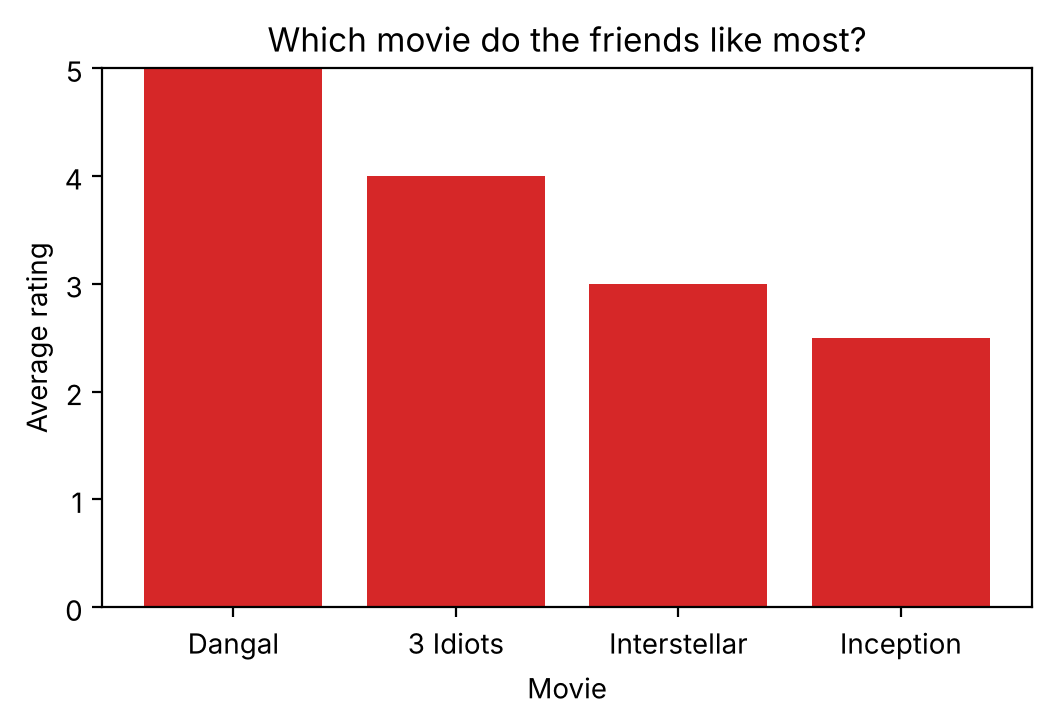

In [22]:
import matplotlib.pyplot as plt

# Bar chart: average rating per movie
plt.figure(figsize=(6, 3.5))
plt.bar(per_movie.index, per_movie["mean"], color="tab:red")
plt.xlabel("Movie")
plt.ylabel("Average rating")
plt.title("Which movie do the friends like most?")
plt.ylim(0, 5)
plt.show()

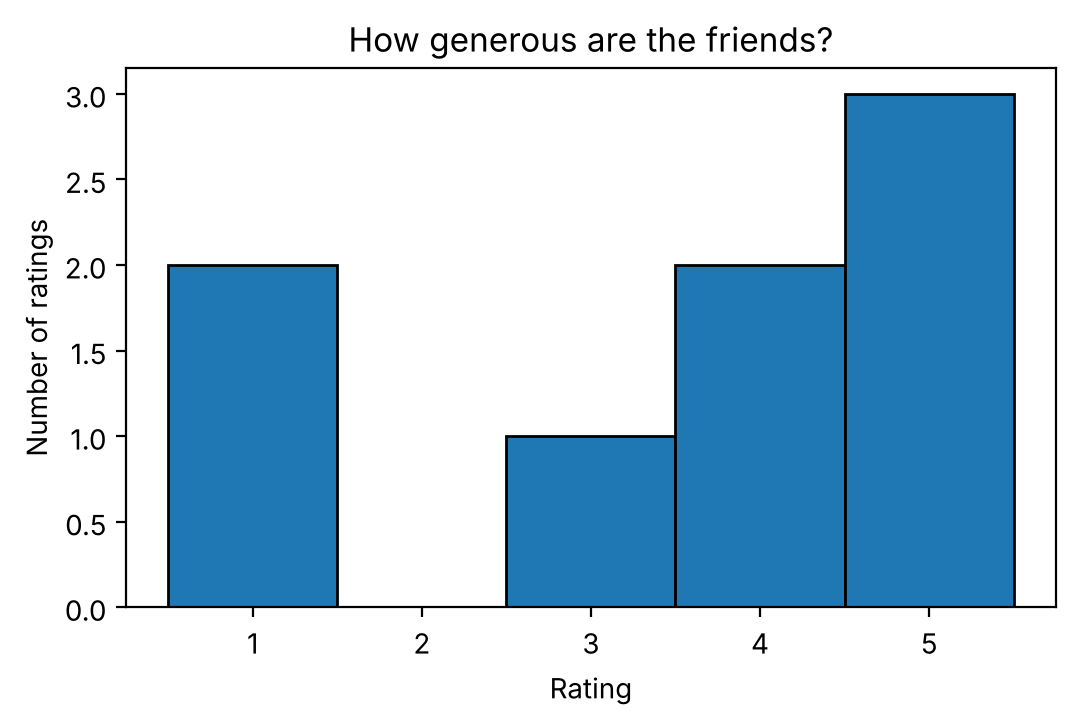

In [23]:
# Histogram: how often each rating value appears
plt.figure(figsize=(6, 3.5))
plt.hist(ratings_df["rating"], bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5], edgecolor="black")
plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.title("How generous are the friends?")
plt.show()

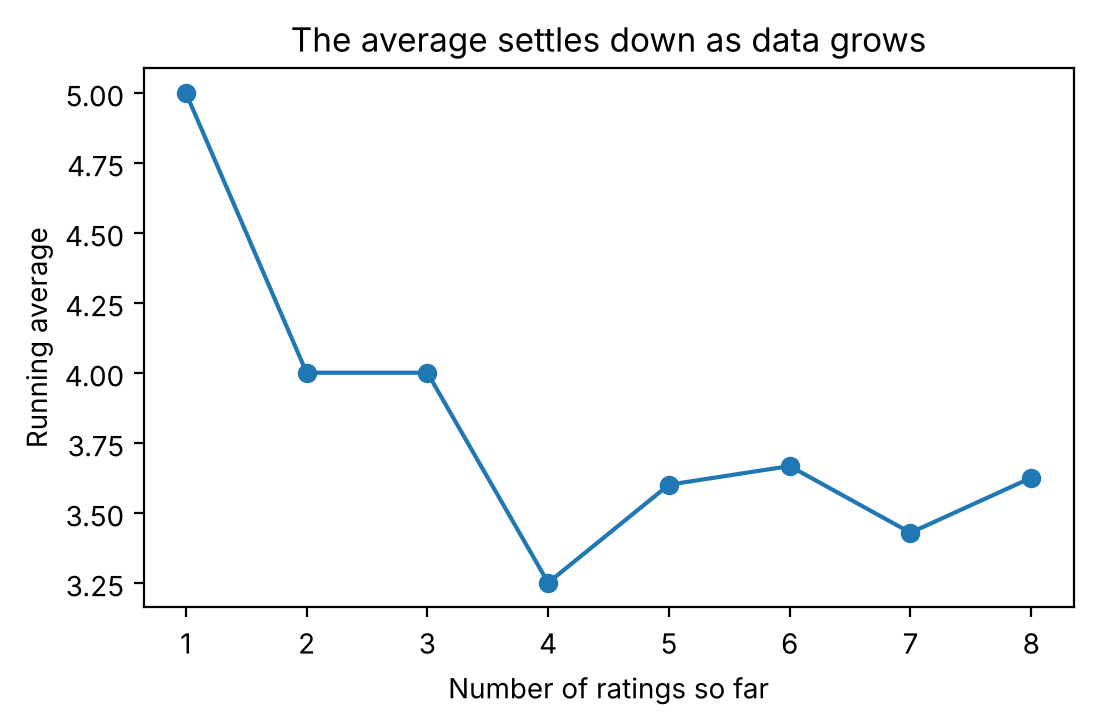

In [24]:
# Line plot: running average as ratings come in one by one
new_ratings = [5, 3, 4, 1, 5, 4, 2, 5]
running = []
total = 0
for i in range(len(new_ratings)):
    total = total + new_ratings[i]
    running.append(total / (i + 1))

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(new_ratings) + 1), running, marker="o")
plt.xlabel("Number of ratings so far")
plt.ylabel("Running average")
plt.title("The average settles down as data grows")
plt.show()

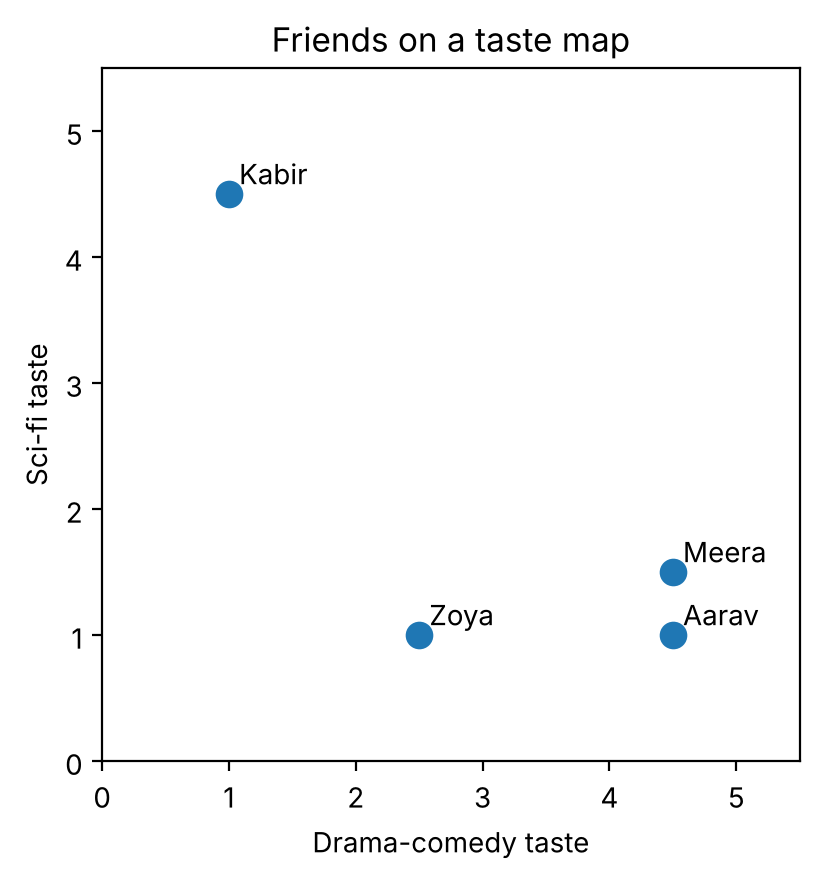

In [25]:
# Scatter plot: each friend as a point (taste for comedy vs sci-fi)
comedy = ratings[:, 0:2].mean(axis=1)   # average of the first two movies
scifi = ratings[:, 2:4].mean(axis=1)    # average of the last two movies
names = ["Aarav", "Meera", "Kabir", "Zoya"]

plt.figure(figsize=(4.5, 4.5))
plt.scatter(comedy, scifi, s=80)
for i in range(len(names)):
    plt.text(comedy[i] + 0.08, scifi[i] + 0.08, names[i])
plt.xlabel("Drama-comedy taste")
plt.ylabel("Sci-fi taste")
plt.xlim(0, 5.5)
plt.ylim(0, 5.5)
plt.title("Friends on a taste map")
plt.show()

Notice that Aarav, Meera and Zoya sit on one side and Kabir sits far away. Placing things on a map so that similar things are close together is the **one idea** this whole project is about.

**Try it 5.** Make a bar chart of the average rating per **genre** (use `full.groupby("genre")["rating"].mean()`). Label both axes.

In [26]:
# Try it 5

---
## Part 6: Mini challenge (all tools together)

1. Create `Movie` objects for the four movies from `ratings_df` and add each rating to the right movie. (Part 2)
2. Print a `describe()` line for each movie.
3. Build a DataFrame with columns `movie`, `average`, `count` from your objects. (Part 4)
4. Draw a bar chart of the averages. (Part 5)

A starting point is given. Fill in the `...` parts.

In [27]:
# Step 1: one Movie object per title
movie_objects = {}
for i in range(len(movies_df)):
    title = movies_df["movie"][i]
    genre = movies_df["genre"][i]
    movie_objects[title] = Movie(title, genre)

# Add each rating from ratings_df to the right movie
for i in range(len(ratings_df)):
    title = ratings_df["movie"][i]
    stars = ratings_df["rating"][i]
    ...   # your line here

# Step 2, 3, 4: your code here

---
## Answers

Try each one yourself first!

In [28]:
# Try it 1
meera_ratings = [4, 5, 1, 2]
print(average(meera_ratings))

3.0


In [29]:
# Try it 2: add this inside the Movie class
#     def count_ratings(self):
#         return len(self.ratings)
# A quick check without editing the class:
print(len(idiots.ratings))

4


In [30]:
# Try it 3
movie_names = ["3 Idiots", "Dangal", "Interstellar", "Inception"]
best = np.argmax(ratings.mean(axis=0))
print(movie_names[best])

3 Idiots


In [31]:
# Try it 4
full.groupby("friend")["rating"].mean().sort_values(ascending=False)

friend
Kabir    4.5
Meera    4.5
Aarav    3.0
Zoya     2.0
Name: rating, dtype: float64

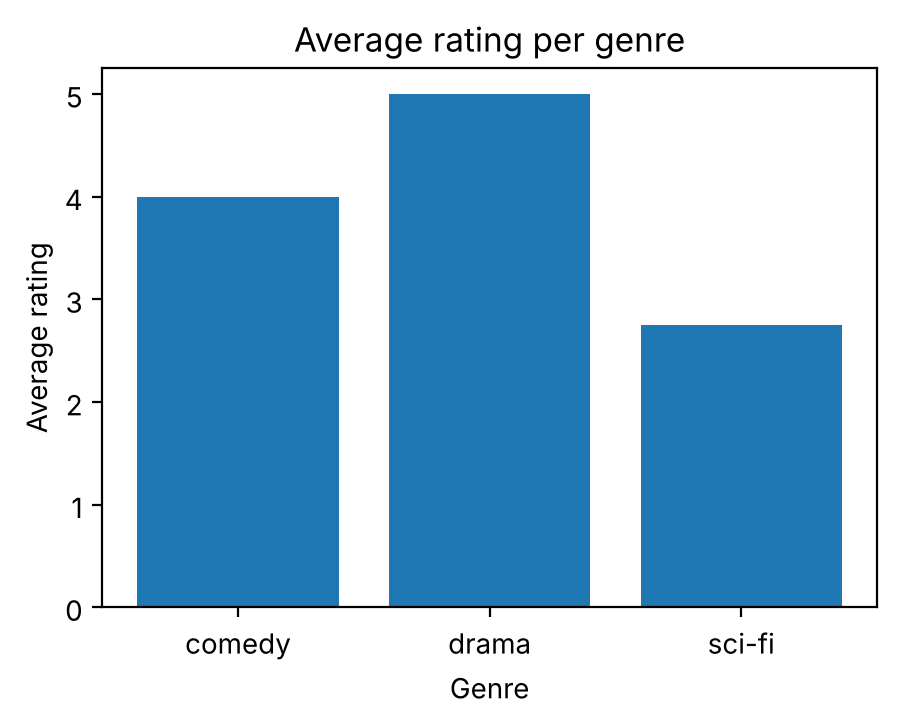

In [32]:
# Try it 5
per_genre = full.groupby("genre")["rating"].mean()
plt.figure(figsize=(5, 3.5))
plt.bar(per_genre.index, per_genre.values)
plt.xlabel("Genre")
plt.ylabel("Average rating")
plt.title("Average rating per genre")
plt.show()

3 Idiots (comedy): 3 ratings, average 4.0
Dangal (drama): 1 ratings, average 5.0
Interstellar (sci-fi): 2 ratings, average 3.0
Inception (sci-fi): 2 ratings, average 2.5
          movie  average  count
0      3 Idiots      4.0      3
1        Dangal      5.0      1
2  Interstellar      3.0      2
3     Inception      2.5      2


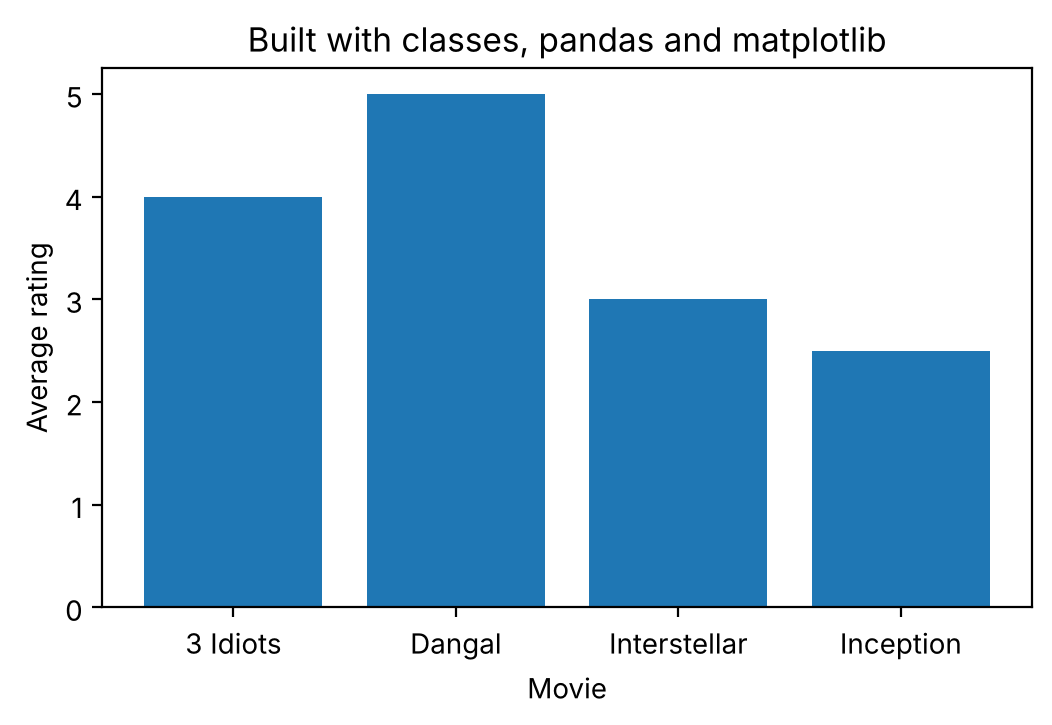

In [33]:
# Mini challenge
movie_objects = {}
for i in range(len(movies_df)):
    title = movies_df["movie"][i]
    genre = movies_df["genre"][i]
    movie_objects[title] = Movie(title, genre)

for i in range(len(ratings_df)):
    title = ratings_df["movie"][i]
    stars = ratings_df["rating"][i]
    movie_objects[title].add_rating(stars)

rows = []
for title in movie_objects:
    m = movie_objects[title]
    m.describe()
    rows.append({"movie": title, "average": m.average_rating(), "count": len(m.ratings)})

summary = pd.DataFrame(rows)
print(summary)

plt.figure(figsize=(6, 3.5))
plt.bar(summary["movie"], summary["average"])
plt.xlabel("Movie")
plt.ylabel("Average rating")
plt.title("Built with classes, pandas and matplotlib")
plt.show()

---
## Cheat sheet

| I want to... | Code |
|---|---|
| Make an array | `np.array([1, 2, 3])` |
| Average of an array | `a.mean()` |
| Dot product | `np.dot(a, b)` |
| Read a CSV | `pd.read_csv("file.csv")` |
| First rows of a table | `df.head()` |
| Filter rows | `df[df["rating"] >= 4]` |
| Summarise per group | `df.groupby("movie")["rating"].mean()` |
| Join two tables | `pd.merge(a, b, on="movie")` |
| Make a grid | `df.pivot_table(index=..., columns=..., values=...)` |
| Bar chart | `plt.bar(x, heights)` |
| Histogram | `plt.hist(values)` |

## Want more practice?

All links are in the main README of the repository, under **Week 0**.

**You are ready for Week 1**, where these four friends teach us how to measure whose taste is closest.